# SMOTE Imbalance Experiment — AI4I Predictive Maintenance Analytics

I investigate whether synthetic minority oversampling improves failure detection compared with an unweighted Random Forest and class weighting.

**Input:** `data/cleaned/ai4i2020_cleaned.csv`  
**Outputs:** tables and experiment settings in `reports/smote/`, and charts in `visuals/smote/`. These folders are created when this notebook runs.

I compare the approaches using the same splits, predictor columns, and Random Forest settings. I calculate the results before choosing a provisional approach; I do not assume that oversampling will improve performance.


## 1. Set up the experiment

I use pandas, scikit-learn, imbalanced-learn, and matplotlib. If imbalanced-learn is missing from the selected notebook kernel, run `%pip install imbalanced-learn` in a separate cell and restart the kernel before continuing.


In [1]:
from pathlib import Path
import hashlib
import json
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import sklearn
try:
    import imblearn
    from imblearn.over_sampling import SMOTENC
    from imblearn.pipeline import Pipeline as ImbalancedPipeline
except ImportError as exc:
    raise ImportError(
        "Install imbalanced-learn in this notebook kernel with "
        "%pip install imbalanced-learn, restart the kernel, and rerun."
    ) from exc

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
N_ESTIMATORS = 100
N_SPLITS = 3
THRESHOLD = 0.5

plt.rcParams["figure.figsize"] = (9, 5)
print(f"Python: {platform.python_version()}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"imbalanced-learn: {imblearn.__version__}")


Python: 3.13.5
scikit-learn: 1.6.1
imbalanced-learn: 0.13.0


## 2. Load and validate the cleaned dataset

I load the output of the cleaning notebook directly. I require a complete binary target, valid product categories, and finite sensor readings before the experiment starts. I record the input checksum so I can check that this notebook leaves the dataset unchanged.


In [2]:
current = Path.cwd().resolve()
PROJECT_ROOT = next(
    (folder for folder in (current, *current.parents)
     if (folder / "data" / "cleaned" / "ai4i2020_cleaned.csv").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Cannot find data/cleaned/ai4i2020_cleaned.csv. "
        "Run 03_data_cleaning.ipynb inside this project first."
    )

DATA_PATH = PROJECT_ROOT / "data" / "cleaned" / "ai4i2020_cleaned.csv"
REPORTS_DIR = PROJECT_ROOT / "reports" / "smote"
VISUALS_DIR = PROJECT_ROOT / "visuals" / "smote"
input_sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()

df = pd.read_csv(DATA_PATH)
TARGET = "Machine failure"
NUMERIC_FEATURES = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]
FEATURES = NUMERIC_FEATURES + ["Type"]
EXCLUDED_FEATURES = ["UDI", "Product ID", TARGET, "TWF", "HDF", "PWF", "OSF", "RNF"]

required_columns = ["UDI", *FEATURES, TARGET]
missing_columns = sorted(set(required_columns) - set(df.columns))
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")
if df.empty or df[required_columns].isna().any().any():
    raise ValueError("Required experiment columns must contain complete observations.")
if not df[TARGET].isin([0, 1]).all() or df[TARGET].nunique() != 2:
    raise ValueError("Machine failure must contain both 0 and 1, without other values.")
if not df["Type"].isin(["L", "M", "H"]).all():
    raise ValueError("Type must contain only L, M, or H.")
if not np.isfinite(df[NUMERIC_FEATURES].to_numpy(dtype=float)).all():
    raise ValueError("Sensor readings must be numeric and finite.")
if df["UDI"].duplicated().any():
    raise ValueError("UDI values must be unique for the split manifest.")

X = df[FEATURES].copy()
y = df[TARGET].astype(int).copy()
assert not set(X.columns).intersection(EXCLUDED_FEATURES)

REPORTS_DIR.mkdir(parents=True, exist_ok=True)
VISUALS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Rows: {len(df):,}; failure observations: {int(y.sum()):,}")
print(f"Failure rate: {y.mean():.2%}")
print(f"Predictor columns: {FEATURES}")
display(df[required_columns].head())


Rows: 10,000; failure observations: 339
Failure rate: 3.39%
Predictor columns: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Type']


,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Type,Machine failure
0,1,298.1,308.6,1551,42.8,0,M,0
1,2,298.2,308.7,1408,46.3,3,L,0
2,3,298.1,308.5,1498,49.4,5,L,0
3,4,298.2,308.6,1433,39.5,7,L,0
4,5,298.2,308.7,1408,40.0,9,L,0


## 3. Separate training, validation, and final test observations

I reserve 20% for a final test set. I then split the remaining observations into training and validation sets, producing approximately **64% training, 16% validation, and 20% final test** overall.

I use stratification to preserve the failure proportion. I fit and cross-validate on training data and compare validation results. I leave the final test set unevaluated in this experiment.


In [3]:
X_development, X_test, y_development, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y,
)
X_train, X_validation, y_train, y_validation = train_test_split(
    X_development, y_development,
    test_size=0.20, random_state=SEED, stratify=y_development,
)

train_indices = set(X_train.index)
validation_indices = set(X_validation.index)
test_indices = set(X_test.index)
assert train_indices.isdisjoint(validation_indices)
assert train_indices.isdisjoint(test_indices)
assert validation_indices.isdisjoint(test_indices)
assert train_indices | validation_indices | test_indices == set(X.index)

split_summary = pd.DataFrame([
    {
        "split": name,
        "observations": len(labels),
        "no_failure": int(labels.eq(0).sum()),
        "failure": int(labels.eq(1).sum()),
        "failure_rate_pct": float(labels.mean()) * 100,
    }
    for name, labels in [
        ("train", y_train), ("validation", y_validation), ("final_test", y_test)
    ]
]).set_index("split")
display(split_summary.round(2))


,observations,no_failure,failure,failure_rate_pct
split,,,,
train,6400,6183,217,3.39
validation,1600,1546,54,3.38
final_test,2000,1932,68,3.40


## 4. Choose the appropriate SMOTE variant

The inputs contain numeric sensor measurements and the categorical `Type` column, so I use **SMOTENC**, the SMOTE variant for mixed numeric and categorical data. I standardize numeric inputs before finding neighbors, resample training rows, and one-hot encode Type afterward.

I place these steps inside an imbalanced-learn pipeline so preprocessing and oversampling are fitted separately within each training fold. Validation and final test rows are not resampled.

References: [SMOTENC documentation](https://imbalanced-learn.org/stable/references/generated/imblearn.over_sampling.SMOTENC.html), [data leakage and resampling](https://imbalanced-learn.org/stable/common_pitfalls.html).

I compare a fixed experiment configuration rather than tuning multiple sampling ratios. Synthetic rows preserve valid product categories, but interpolation does not guarantee engineering validity for every combination of sensor readings.


In [4]:
def make_pipeline(use_smote=False, class_weight=None):
    # Preserve Type as a category until after oversampling.
    scale_numeric = ColumnTransformer(
        [
            ("numeric", StandardScaler(), NUMERIC_FEATURES),
            ("category", "passthrough", ["Type"]),
        ],
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")

    encode_category = ColumnTransformer(
        [
            ("numeric", "passthrough", NUMERIC_FEATURES),
            ("category", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["Type"]),
        ],
        verbose_feature_names_out=False,
    )

    sampler = (
        SMOTENC(
            categorical_features=["Type"],
            sampling_strategy="auto",
            k_neighbors=5,
            random_state=SEED,
        )
        if use_smote else "passthrough"
    )

    return ImbalancedPipeline([
        ("scale", scale_numeric),
        ("sampler", sampler),
        ("encode", encode_category),
        ("classifier", RandomForestClassifier(
            n_estimators=N_ESTIMATORS,
            class_weight=class_weight,
            random_state=SEED,
            n_jobs=-1,
        )),
    ])

candidates = {
    "Baseline": make_pipeline(),
    "Class weighting": make_pipeline(class_weight="balanced"),
    "SMOTENC": make_pipeline(use_smote=True),
}

cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
for fold_train, _ in cv.split(X_train, y_train):
    if y_train.iloc[fold_train].value_counts().min() <= 5:
        raise ValueError("Each training fold needs more than 5 observations in both classes.")
print("Created three independent pipelines with the same Random Forest settings.")


Created three independent pipelines with the same Random Forest settings.


## 5. Inspect the training-only resampling

I inspect class counts before and after SMOTENC on the training set. This audit uses a separate copy of the preprocessing and sampler, which is not used to generate validation or test data.

For this fixed binary experiment, the sampler increases the minority class to the majority-class count. This does not change the observed failure prevalence in validation data.


,training_before,training_after_SMOTENC
Machine failure,,
0,6183,6183
1,217,6183


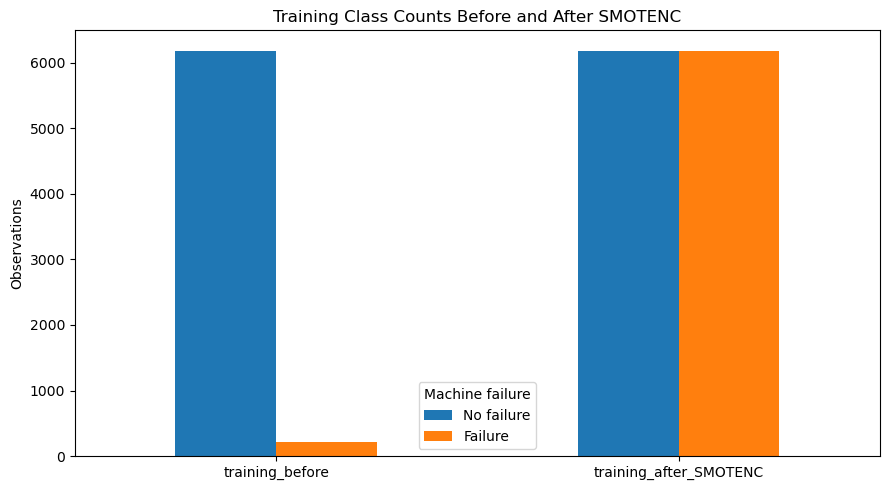

In [5]:
audit_scale = clone(candidates["SMOTENC"].named_steps["scale"])
audit_sampler = clone(candidates["SMOTENC"].named_steps["sampler"])
X_train_scaled = audit_scale.fit_transform(X_train, y_train)
X_resampled, y_resampled = audit_sampler.fit_resample(X_train_scaled, y_train)

assert set(X_resampled["Type"].unique()).issubset(set(X_train["Type"].unique()))
assert np.isfinite(X_resampled[NUMERIC_FEATURES].to_numpy(dtype=float)).all()

resampling_summary = pd.DataFrame({
    "training_before": y_train.value_counts().reindex([0, 1], fill_value=0),
    "training_after_SMOTENC": pd.Series(y_resampled).value_counts().reindex([0, 1], fill_value=0),
}).rename_axis("Machine failure")
display(resampling_summary)

fig, ax = plt.subplots(figsize=(9, 5))
resampling_summary.T.rename(columns={0: "No failure", 1: "Failure"}).plot.bar(ax=ax)
ax.set_title("Training Class Counts Before and After SMOTENC")
ax.set_xlabel("")
ax.set_ylabel("Observations")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig(VISUALS_DIR / "training_resampling_counts.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)


## 6. Compare methods within training cross-validation

I use the same three stratified folds for each method. I report mean average precision and its fold-to-fold standard deviation, along with precision, recall, F1, and ROC-AUC.

Average precision summarizes the precision–recall tradeoff; it is not the trapezoidal area under the precision–recall curve. Precision, recall, and F1 here use each classifier's default decision rule, corresponding to an operating threshold of approximately 0.5.


In [6]:
scoring = {
    "average_precision": "average_precision",
    "roc_auc": "roc_auc",
    "recall": "recall",
    "precision": "precision",
    "f1": "f1",
}
cv_rows = []
cv_fold_rows = []
for name, pipeline in candidates.items():
    print(f"Cross-validating: {name}")
    scores = cross_validate(
        pipeline, X_train, y_train, cv=cv,
        scoring=scoring, n_jobs=1, error_score="raise",
    )
    row = {"method": name}
    for metric in scoring:
        values = scores[f"test_{metric}"]
        row[f"{metric}_mean"] = float(values.mean())
        row[f"{metric}_std"] = float(values.std(ddof=1))
    cv_rows.append(row)
    for fold_number in range(N_SPLITS):
        cv_fold_rows.append({
            "method": name,
            "fold": fold_number + 1,
            **{
                metric: float(scores[f"test_{metric}"][fold_number])
                for metric in scoring
            },
        })

cv_results = pd.DataFrame(cv_rows).set_index("method")
cv_fold_results = pd.DataFrame(cv_fold_rows)
display(cv_results.round(4))


Cross-validating: Baseline


Cross-validating: Class weighting


Cross-validating: SMOTENC


,average_precision_mean,average_precision_std,roc_auc_mean,roc_auc_std,recall_mean,recall_std,precision_mean,precision_std,f1_mean,f1_std
method,,,,,,,,,,
Baseline,0.7245,0.0406,0.9622,0.0131,0.4195,0.0338,0.8756,0.0413,0.5667,0.0351
Class weighting,0.6730,0.0471,0.9580,0.0129,0.3040,0.0214,0.8701,0.0382,0.4501,0.0222
SMOTENC,0.6272,0.0219,0.9599,0.0119,0.7139,0.0851,0.4959,0.0084,0.5835,0.0242


## 7. Compare performance on the validation set

I fit each pipeline on the full training set and evaluate it on the unchanged validation rows. I use a common probability threshold of **0.5** for the classification metrics and report average precision and ROC-AUC from the score rankings.

This experiment does not optimize a deployment threshold. Oversampling changes the training class balance, so its probability scores should not be treated as calibrated failure risks without further evaluation.


In [7]:
validation_rows = []
validation_predictions = {}
fitted_models = {}

for name, candidate in candidates.items():
    model = clone(candidate)
    model.fit(X_train, y_train)
    positive_column = int(np.flatnonzero(model.classes_ == 1)[0])
    probabilities = model.predict_proba(X_validation)[:, positive_column]
    predictions = (probabilities >= THRESHOLD).astype(int)

    fitted_models[name] = model
    validation_predictions[name] = (predictions, probabilities)
    validation_rows.append({
        "method": name,
        "threshold": THRESHOLD,
        "average_precision": float(average_precision_score(y_validation, probabilities)),
        "roc_auc": float(roc_auc_score(y_validation, probabilities)),
        "recall": float(recall_score(y_validation, predictions, zero_division=0)),
        "precision": float(precision_score(y_validation, predictions, zero_division=0)),
        "f1": float(f1_score(y_validation, predictions, zero_division=0)),
        "false_negatives": int(((y_validation.to_numpy() == 1) & (predictions == 0)).sum()),
        "false_positives": int(((y_validation.to_numpy() == 0) & (predictions == 1)).sum()),
    })

validation_results = pd.DataFrame(validation_rows).set_index("method")
display(validation_results.round(4))

for name, (predictions, _) in validation_predictions.items():
    print(f"\n{name} — validation")
    print(classification_report(
        y_validation, predictions,
        labels=[0, 1], target_names=["No failure", "Failure"], zero_division=0,
    ))


,threshold,average_precision,roc_auc,recall,precision,f1,false_negatives,false_positives
method,,,,,,,,
Baseline,0.5,0.7712,0.9564,0.5556,0.9091,0.6897,24,3
Class weighting,0.5,0.7444,0.9667,0.4444,0.9231,0.6000,30,2
SMOTENC,0.5,0.6411,0.9608,0.7222,0.4286,0.5379,15,52



Baseline — validation
              precision    recall  f1-score   support

  No failure       0.98      1.00      0.99      1546
     Failure       0.91      0.56      0.69        54

    accuracy                           0.98      1600
   macro avg       0.95      0.78      0.84      1600
weighted avg       0.98      0.98      0.98      1600


Class weighting — validation
              precision    recall  f1-score   support

  No failure       0.98      1.00      0.99      1546
     Failure       0.92      0.44      0.60        54

    accuracy                           0.98      1600
   macro avg       0.95      0.72      0.79      1600
weighted avg       0.98      0.98      0.98      1600


SMOTENC — validation
              precision    recall  f1-score   support

  No failure       0.99      0.97      0.98      1546
     Failure       0.43      0.72      0.54        54

    accuracy                           0.96      1600
   macro avg       0.71      0.84      0.76      1600

## 8. Review errors and precision–recall curves

I compare missed failures and false alarms at the fixed threshold using confusion matrices. I also plot precision–recall curves to compare score rankings across thresholds while retaining the validation set's observed class balance.


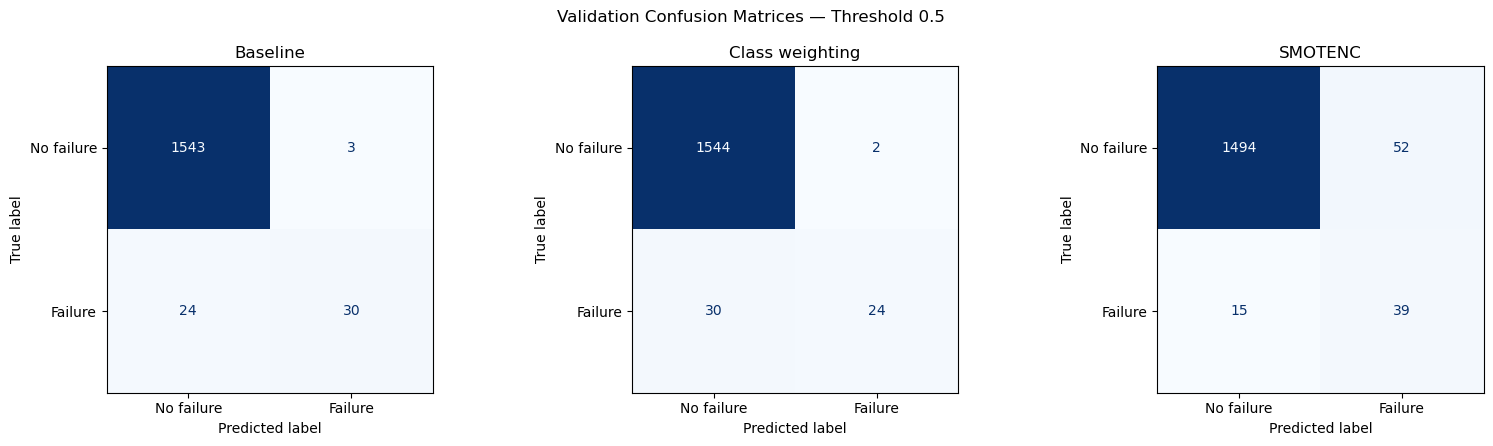

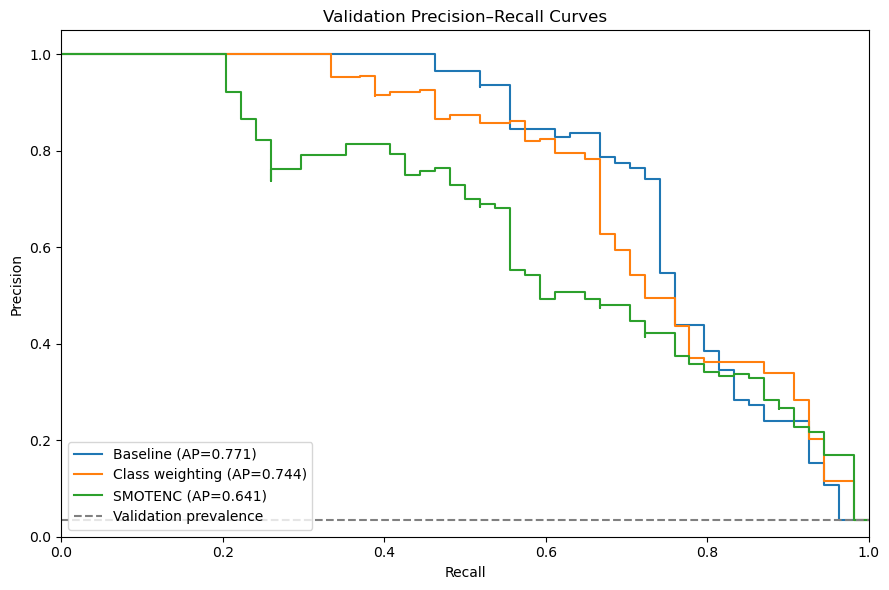

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, (predictions, _)) in zip(axes, validation_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_validation, predictions, labels=[0, 1],
        display_labels=["No failure", "Failure"],
        colorbar=False, ax=ax, cmap="Blues",
    )
    ax.set_title(name)
fig.suptitle("Validation Confusion Matrices — Threshold 0.5")
plt.tight_layout()
plt.savefig(VISUALS_DIR / "validation_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(9, 6))
for name, (_, probabilities) in validation_predictions.items():
    precision_values, recall_values, _ = precision_recall_curve(y_validation, probabilities)
    ap = validation_results.loc[name, "average_precision"]
    ax.step(recall_values, precision_values, where="post", label=f"{name} (AP={ap:.3f})")
ax.axhline(y_validation.mean(), color="gray", linestyle="--", label="Validation prevalence")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Validation Precision–Recall Curves")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)
ax.legend(loc="lower left")
plt.tight_layout()
plt.savefig(VISUALS_DIR / "validation_precision_recall_curves.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)


## 9. Record the experiment results

I save fold-level and aggregate metrics, class counts, settings, and a split manifest. These files make the comparison reproducible.

The results identify the method with the highest mean training cross-validation average precision for this configuration. That is a provisional observation, not proof of a statistically significant advantage or a final deployment decision. I leave final test performance unmeasured here.


In [9]:
cv_leader = str(cv_results["average_precision_mean"].idxmax())
validation_leader = str(validation_results["average_precision"].idxmax())

print(f"Highest mean training CV average precision: {cv_leader}")
print(f"Highest validation average precision: {validation_leader}")

for metric in ["average_precision", "recall", "precision", "f1"]:
    change = validation_results.loc["SMOTENC", metric] - validation_results.loc["Baseline", metric]
    print(f"SMOTENC minus baseline validation {metric}: {change:+.4f}")

print("\nI will assess the recall / false-alarm tradeoff and stability before selecting a method.")
print("Final test observations have not been scored in this notebook.")

split_manifest = pd.DataFrame({
    "UDI": df["UDI"],
    "Machine failure": y,
    "split": "unassigned",
})
split_manifest.loc[X_train.index, "split"] = "train"
split_manifest.loc[X_validation.index, "split"] = "validation"
split_manifest.loc[X_test.index, "split"] = "final_test"
assert not split_manifest["split"].eq("unassigned").any()

settings = {
    "input_relative_path": DATA_PATH.relative_to(PROJECT_ROOT).as_posix(),
    "input_sha256": input_sha256,
    "seed": SEED,
    "features": FEATURES,
    "excluded_columns": EXCLUDED_FEATURES,
    "random_forest_estimators": N_ESTIMATORS,
    "cv_splits": N_SPLITS,
    "validation_threshold": THRESHOLD,
    "sampling_method": "SMOTENC",
    "sampling_strategy": "auto",
    "smote_k_neighbors": 5,
    "category_encoding": "one-hot after resampling",
    "numeric_scaling": "StandardScaler fitted within each training fold",
    "final_test_scored": False,
    "highest_mean_training_cv_AP": cv_leader,
    "highest_validation_AP": validation_leader,
    "versions": {
        "python": platform.python_version(),
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "scikit_learn": sklearn.__version__,
        "imbalanced_learn": imblearn.__version__,
    },
}

cv_results.to_csv(REPORTS_DIR / "cross_validation_results.csv")
cv_fold_results.to_csv(REPORTS_DIR / "cross_validation_folds.csv", index=False)
validation_results.to_csv(REPORTS_DIR / "validation_results.csv")
split_summary.to_csv(REPORTS_DIR / "split_summary.csv")
resampling_summary.to_csv(REPORTS_DIR / "training_resampling_counts.csv")
split_manifest.to_csv(REPORTS_DIR / "split_manifest.csv", index=False)
(REPORTS_DIR / "experiment_settings.json").write_text(
    json.dumps(settings, indent=2, allow_nan=False), encoding="utf-8",
)

if hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() != input_sha256:
    raise RuntimeError("The input CSV changed during the experiment.")

print(f"\nSaved reports to: {REPORTS_DIR.relative_to(PROJECT_ROOT)}")
print(f"Saved charts to: {VISUALS_DIR.relative_to(PROJECT_ROOT)}")
print("Verified: the cleaned input CSV is unchanged.")


Highest mean training CV average precision: Baseline
Highest validation average precision: Baseline
SMOTENC minus baseline validation average_precision: -0.1301
SMOTENC minus baseline validation recall: +0.1667
SMOTENC minus baseline validation precision: -0.4805
SMOTENC minus baseline validation f1: -0.1517

I will assess the recall / false-alarm tradeoff and stability before selecting a method.
Final test observations have not been scored in this notebook.

Saved reports to: reports\smote
Saved charts to: visuals\smote
Verified: the cleaned input CSV is unchanged.


## Next steps

I use this experiment to decide whether oversampling deserves further evaluation. I will compare additional models, select any operating threshold using validation data, and evaluate the finalized approach on the reserved test set.

I do not export synthetic rows into the shared cleaned dataset. If I retain SMOTENC later, it stays inside the training pipeline so each fitting step uses only its own training observations.
